In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [3]:
DATA_PATH = Path(
    "../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print(f"Rows:{df.shape[0]}")
print(f"Columns:{df.shape[1]}")

display(df.head())

Dataset loaded successfully!
Rows:7043
Columns:21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
missing = pd.DataFrame({
    "Missing count" : df.isnull().sum(),
    "Missing Percentage" : df.isnull().mean() * 100
})

display(
    missing.sort_values(
        by="Missing Percentage",
        ascending=False
    )
)

,Missing count,Missing Percentage
customerID,0,0.0
DeviceProtection,0,0.0
TotalCharges,0,0.0
MonthlyCharges,0,0.0
PaymentMethod,0,0.0
PaperlessBilling,0,0.0
Contract,0,0.0
StreamingMovies,0,0.0
StreamingTV,0,0.0
TechSupport,0,0.0


In [7]:
print("Duplicate rows :",df.duplicated().sum())
print(
    "Duplicate customer IDs:",
    df["customerID"].duplicated().sum()
)

Duplicate rows : 0
Duplicate customer IDs: 0


In [9]:
for col in df.columns:
    print(f"{col} : {df[col].nunique()} unique values")

customerID : 7043 unique values
gender : 2 unique values
SeniorCitizen : 2 unique values
Partner : 2 unique values
Dependents : 2 unique values
tenure : 73 unique values
PhoneService : 2 unique values
MultipleLines : 3 unique values
InternetService : 3 unique values
OnlineSecurity : 3 unique values
OnlineBackup : 3 unique values
DeviceProtection : 3 unique values
TechSupport : 3 unique values
StreamingTV : 3 unique values
StreamingMovies : 3 unique values
Contract : 3 unique values
PaperlessBilling : 2 unique values
PaymentMethod : 4 unique values
MonthlyCharges : 1585 unique values
TotalCharges : 6531 unique values
Churn : 2 unique values


In [10]:
print(df["Churn"].value_counts())

print("\nChurn percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [11]:
print(df["TotalCharges"].dtype)

print(
    "Blank TotalCharges :",
    (df["TotalCharges"].astype(str).str.strip() == "").sum()
)

object
Blank TotalCharges : 11


##  Univariate Analysis

In [13]:
numerical_cols = df.select_dtypes(
    include = ["int64","float64"]
).columns.to_list()

categorical_cols = df.select_dtypes(
    include = ["category","object"]
).columns.to_list()

print("Numerical columns :", numerical_cols)
print("Categorical_columns :", categorical_cols)

Numerical columns : ['SeniorCitizen', 'tenure', 'MonthlyCharges']
Categorical_columns : ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']


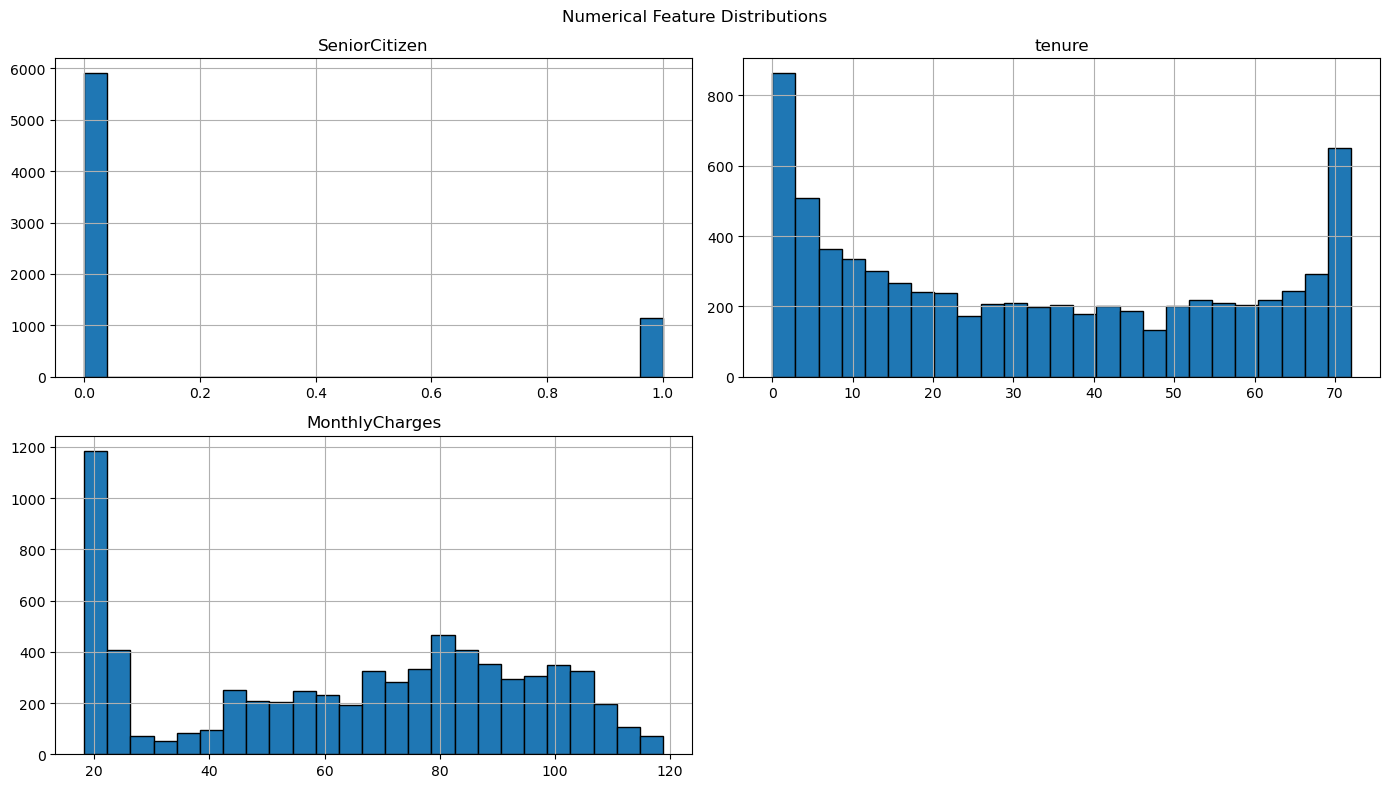

In [14]:
df[numerical_cols].hist(
    bins=25,
    figsize=(14, 8),
    edgecolor="black"
)

plt.suptitle("Numerical Feature Distributions")
plt.tight_layout()
plt.show()

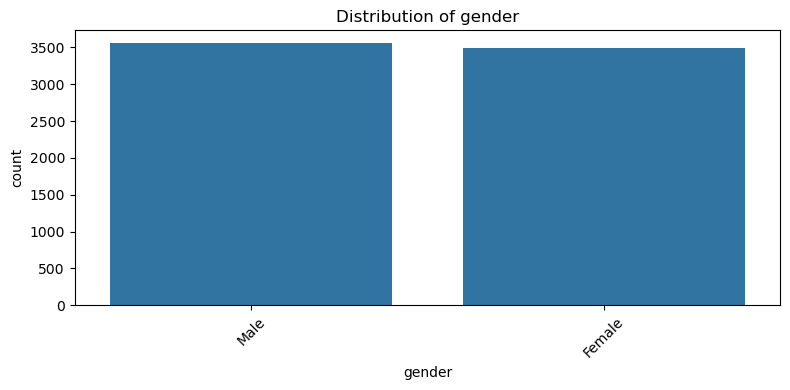

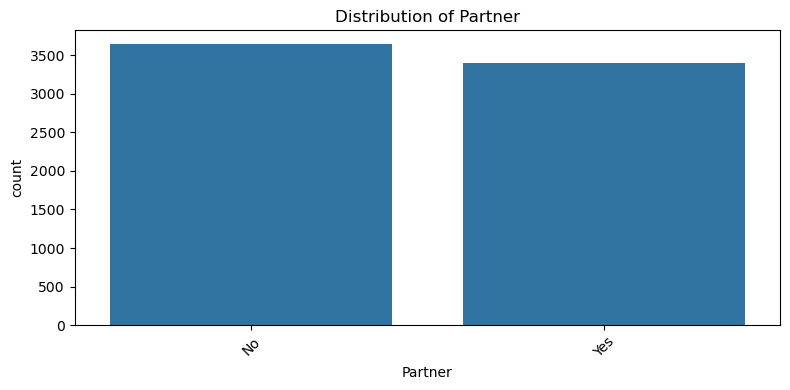

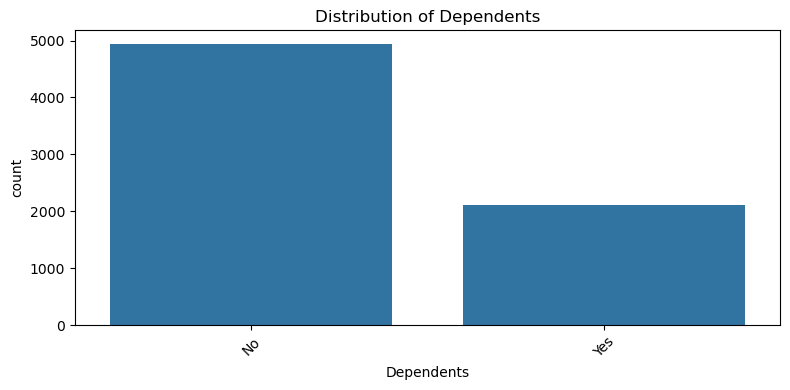

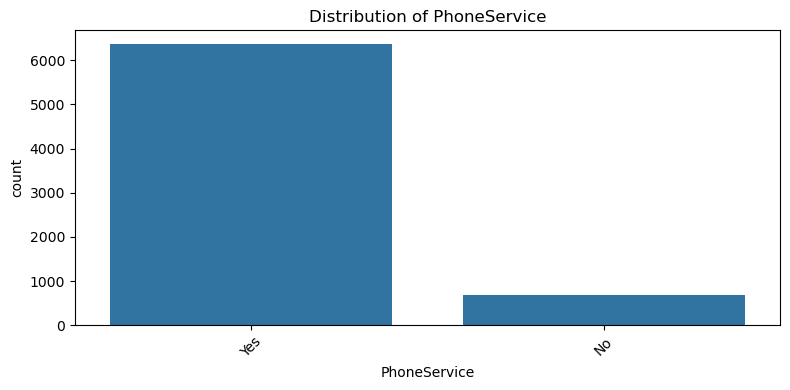

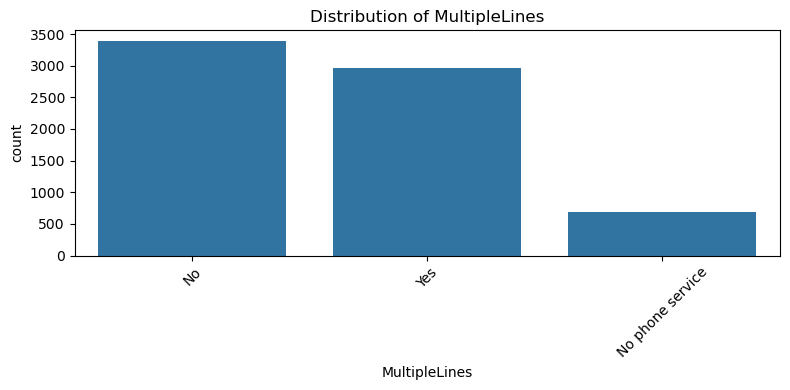

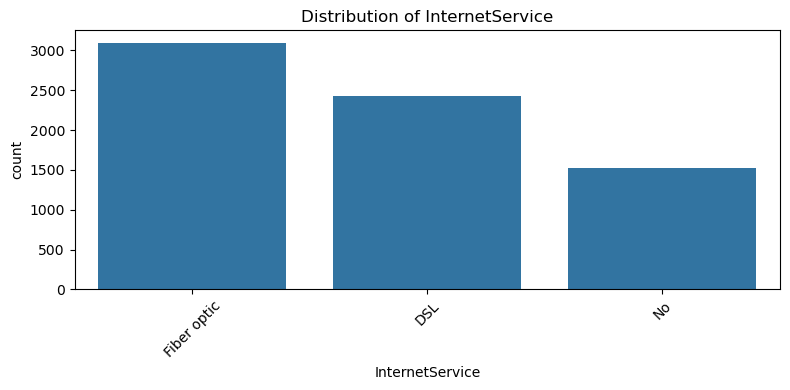

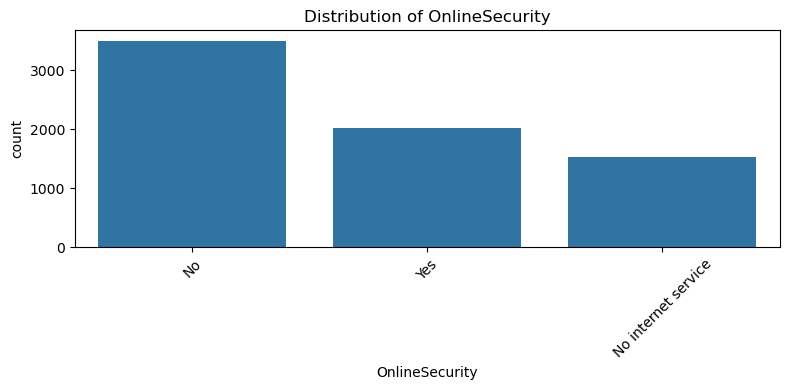

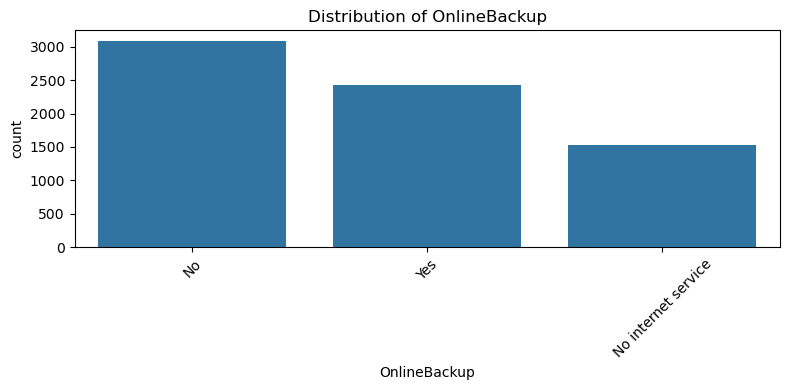

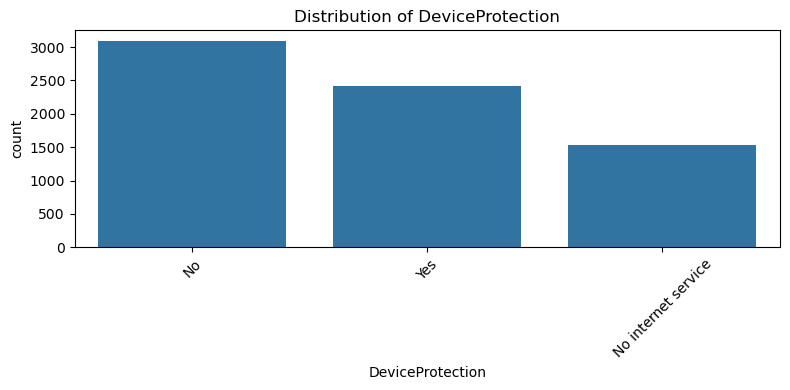

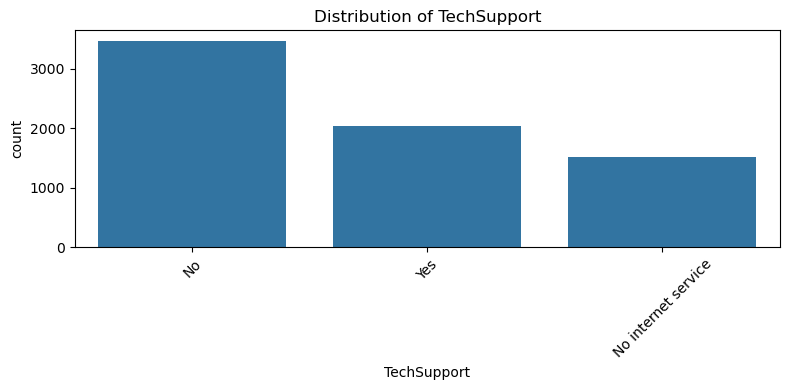

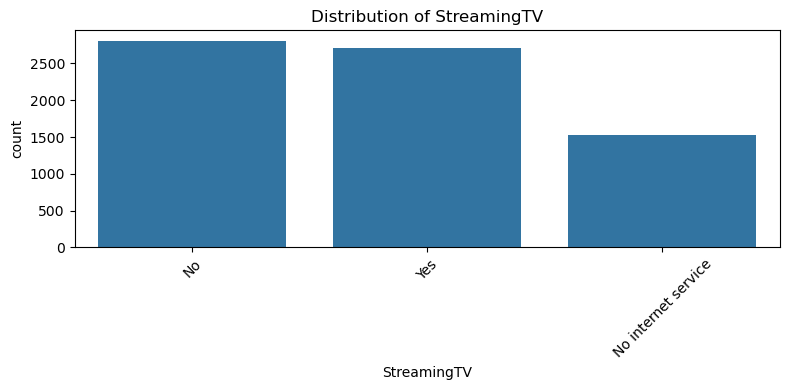

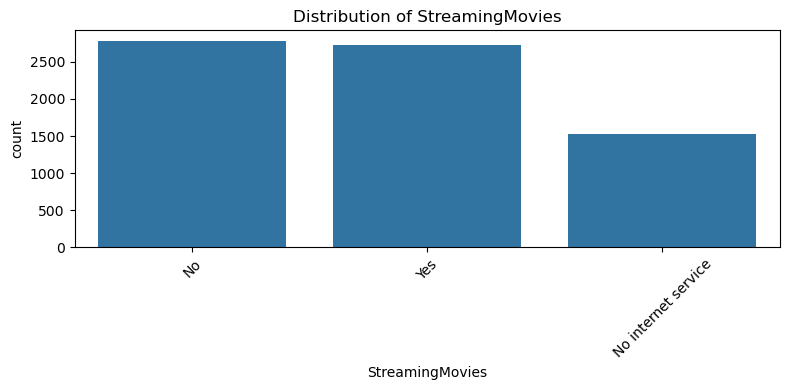

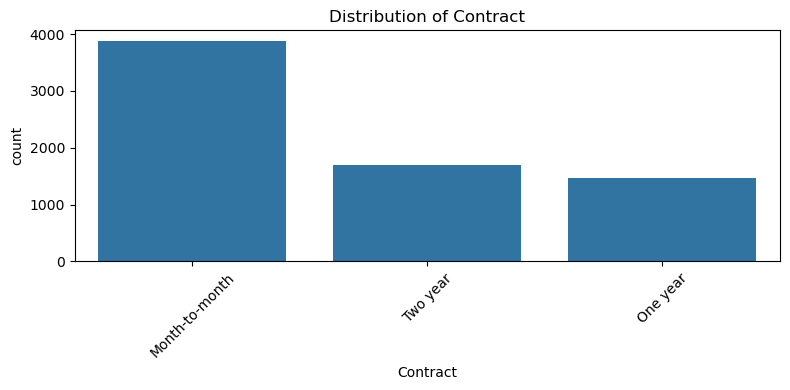

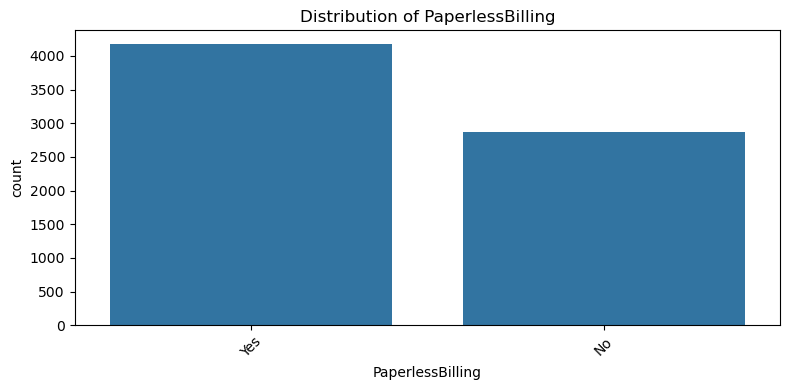

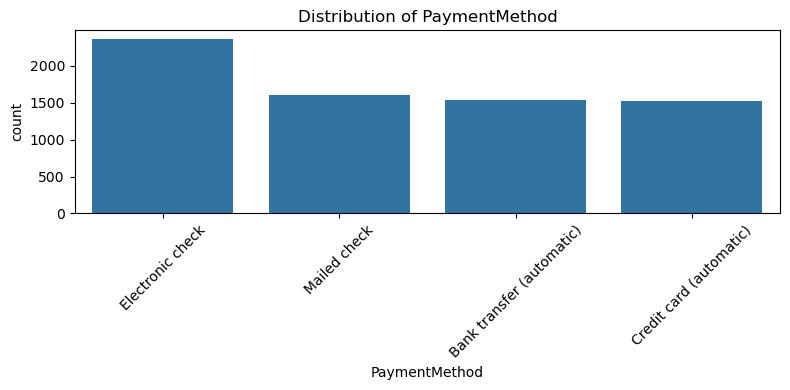

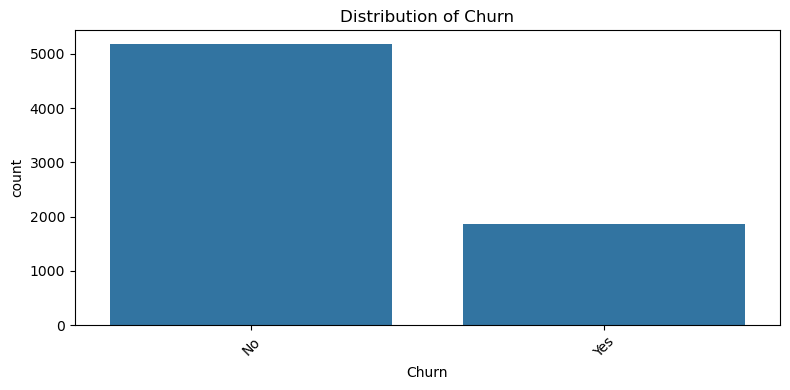

In [15]:
for col in categorical_cols:

    if col in ["customerID", "TotalCharges"]:
        continue

    plt.figure(figsize=(8, 4))

    sns.countplot(
        data=df,
        x=col,
        order=df[col].value_counts().index
    )

    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## Bivariate analysis

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


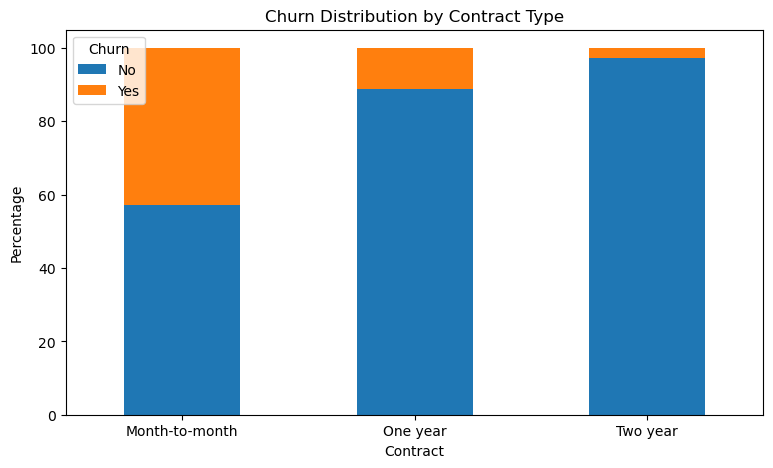

In [16]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

display(contract_churn)

contract_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Churn Distribution by Contract Type")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.show()

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


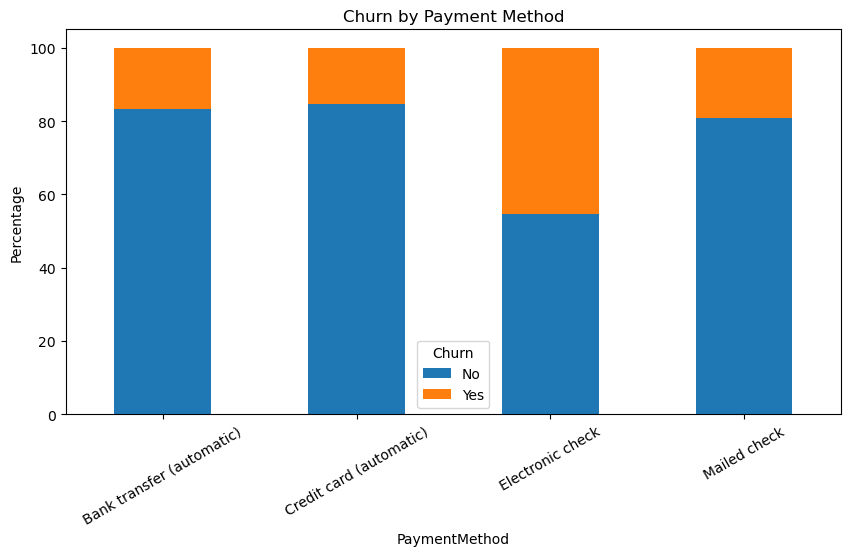

In [17]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

display(payment_churn)

payment_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Churn by Payment Method")
plt.ylabel("Percentage")
plt.xticks(rotation=30)
plt.show()

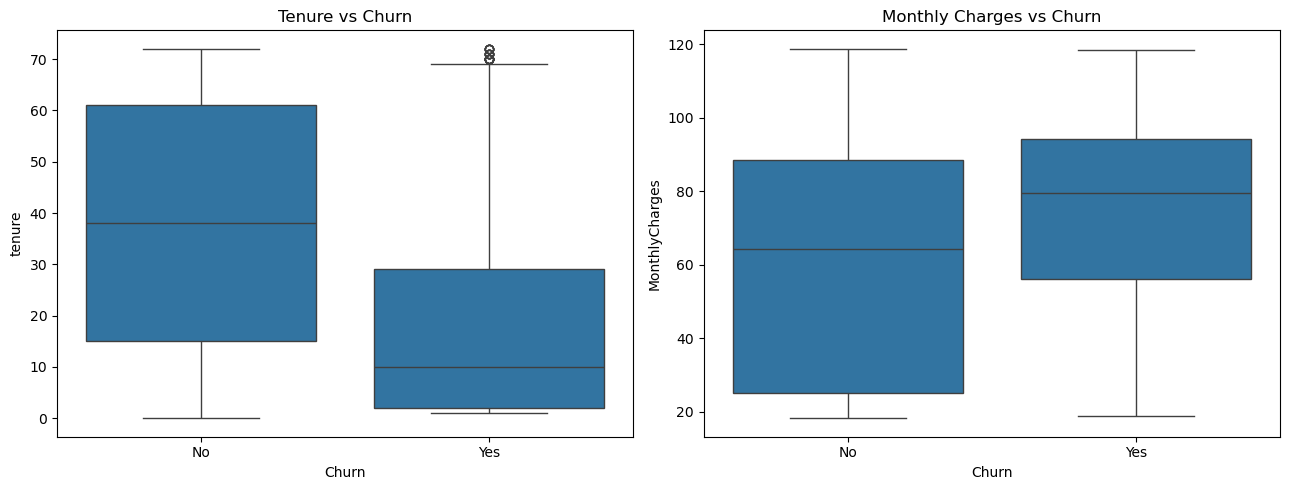

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure",
    ax=axes[0]
)

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    ax=axes[1]
)

axes[0].set_title("Tenure vs Churn")
axes[1].set_title("Monthly Charges vs Churn")

plt.tight_layout()
plt.show()

## Correlation analysis

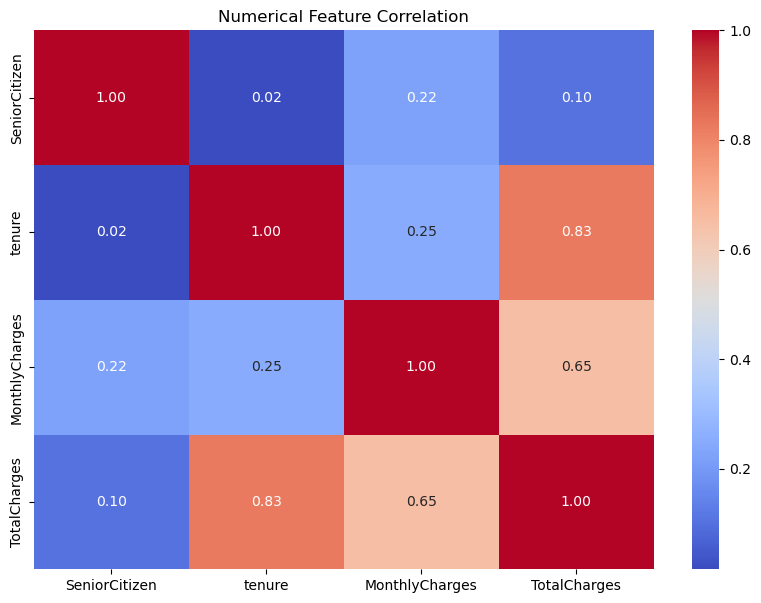

In [19]:
eda_df = df.copy()

eda_df["TotalCharges"] = pd.to_numeric(
    eda_df["TotalCharges"],
    errors="coerce"
)

corr = eda_df.select_dtypes(
    include=np.number
).corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Numerical Feature Correlation")
plt.show()



#  Business Insights and EDA Conclusions

## Key Business Insights

Based on the exploratory data analysis, the following patterns were observed:

**1. Contract Type and Customer Churn**

Customers with month-to-month contracts show a substantially higher churn rate than customers with one-year or two-year contracts. Customers with longer-term contracts appear more likely to remain with the company.

**Business implication:** The company should encourage month-to-month customers to switch to longer-term contracts through loyalty benefits, discounts, and suitable retention offers.

**2. Payment Method and Customer Churn**

Customers using electronic checks have a noticeably higher churn rate compared with customers using other payment methods.

**Business implication:** The company should investigate possible payment-related issues and encourage customers to use more convenient automatic payment methods.

**3. Customer Tenure and Churn**

The boxplot shows that customers who churn generally have considerably lower tenure than customers who stay. This indicates that newer customers are an important risk segment.

**Business implication:** The company should focus on customer onboarding, early engagement, and support during the initial months of the customer relationship.

**4. Monthly Charges and Churn**

Customers who churn tend to have higher monthly charges than customers who remain. This suggests that pricing and perceived service value may be associated with customer churn.

**Business implication:** The company should identify customers with relatively high monthly charges and evaluate whether personalized pricing or suitable service packages could improve retention.

**5. Correlation Between Numerical Features**

The correlation heatmap shows:
- Tenure and TotalCharges have a strong positive correlation (approximately 0.83).
- MonthlyCharges and TotalCharges have a moderate-to-strong positive correlation (approximately 0.65).
- Tenure and MonthlyCharges have a relatively weak positive correlation (approximately 0.25).

This indicates that total customer charges are strongly associated with how long a customer has been subscribed and their monthly charges.

## Additional Dataset Observations

- The target variable, Churn, contains more non-churn customers than churn customers, indicating class imbalance.
- Senior citizens represent a smaller portion of the customer base.
- Tenure and MonthlyCharges show different distributions across customers, making them useful features to investigate during model development.
- The dataset contains both numerical and categorical features, requiring appropriate preprocessing before model training.

## Final EDA Conclusions

The exploratory data analysis reveals that customer churn is associated with multiple customer characteristics rather than a single factor.

Contract type, payment method, tenure, and monthly charges show particularly useful patterns for identifying customer segments with potentially higher churn risk.

These findings will guide the next stages of the project:

1. Data cleaning and handling missing or invalid values.
2. Encoding categorical variables and preparing numerical features.
3. Feature engineering to improve predictive performance.
4. Training and comparing multiple machine learning models.
5. Evaluating model performance using suitable classification metrics, especially Recall, F1-score, and ROC-AUC.

The objective of the next stage is to transform these observations into a reliable customer churn prediction system that can help businesses identify at-risk customers and take proactive retention measures.

**Note:** These findings represent associations observed in the dataset. They do not establish that any particular feature directly causes customer churn.